In [2]:

import os
from dotenv import load_dotenv

load_dotenv(".env")

api_key = os.getenv("API_KEY")

print("API key loaded:", bool(api_key))


API key loaded: True


In [3]:

import requests
import pandas as pd

url = "https://api.collegefootballdata.com/coaches"

headers = {
    "Authorization": f"Bearer {api_key}"
}

response = requests.get(
    url,
    headers=headers,
    params={"year": 2020},
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    coaches = pd.DataFrame(response.json())
    display(coaches.head())
    print("Total coaches:", len(coaches))
    print("Columns:", coaches.columns.tolist())
else:
    print("Request failed:", response.status_code)


Status code: 200


,id,firstName,lastName,hireDate,seasons
0,1,Steve,Addazio,2019-12-10T00:00:00.000Z,"[{'teamId': 36, 'school': 'Colorado State', 'c..."
1,5,Tom,Allen,2016-12-01T00:00:00.000Z,"[{'teamId': 84, 'school': 'Indiana', 'conferen..."
2,9,Gary,Andersen,2018-12-09T00:00:00.000Z,"[{'teamId': 328, 'school': 'Utah State', 'conf..."
3,10,Blake,Anderson,2013-12-19T00:00:00.000Z,"[{'teamId': 2032, 'school': 'Arkansas State', ..."
4,562,Dave,Aranda,2020-01-22T00:00:00.000Z,"[{'teamId': 239, 'school': 'Baylor', 'conferen..."


Total coaches: 137
Columns: ['id', 'firstName', 'lastName', 'hireDate', 'seasons']


In [4]:

from pprint import pprint

print("Coach:", coaches.loc[0, "firstName"], coaches.loc[0, "lastName"])

pprint(coaches.loc[0, "seasons"][0])


Coach: Steve Addazio
{'conference': 'Mountain West',
 'games': 4,
 'losses': 3,
 'postseasonRank': None,
 'preseasonRank': None,
 'school': 'Colorado State',
 'spDefense': 30.5,
 'spOffense': 24.2,
 'spOverall': -6.5,
 'srs': -11.3,
 'teamId': 36,
 'ties': 0,
 'winPercentage': 0.25,
 'wins': 1,
 'year': 2020}


In [5]:

rows = []

for _, coach in coaches.iterrows():
    for season in coach["seasons"]:
        rows.append({
            "coach_id": coach["id"],
            "coach_name": coach["firstName"] + " " + coach["lastName"],
            **season
        })

season_df = pd.DataFrame(rows)

display(season_df[[
    "coach_name",
    "year",
    "school",
    "conference",
    "games",
    "wins",
    "losses",
    "winPercentage"
]].head(10))

print("Total rows:", len(season_df))


,coach_name,year,school,conference,games,wins,losses,winPercentage
0,Steve Addazio,2020,Colorado State,Mountain West,4,1,3,0.250
1,Tom Allen,2020,Indiana,Big Ten,8,6,2,0.750
2,Gary Andersen,2020,Utah State,Mountain West,3,0,3,0.000
3,Blake Anderson,2020,Arkansas State,Sun Belt,11,4,7,0.364
4,Dave Aranda,2020,Baylor,Big 12,9,2,7,0.222
5,Marcus Arroyo,2020,UNLV,Mountain West,6,0,6,0.000
6,Tom Arth,2020,Akron,Mid-American,6,1,5,0.167
7,Dino Babers,2020,Syracuse,ACC,11,1,10,0.091
8,Walt Bell,2020,Massachusetts,FBS Independents,4,0,4,0.000
9,Tim Billings,2020,Southern Miss,Conference USA,5,2,3,0.400


Total rows: 137


In [6]:

print("Conferences in our 2020 data:")

print(season_df["conference"].value_counts())


Conferences in our 2020 data:
conference
SEC                  17
Big Ten              15
ACC                  15
Conference USA       15
Mountain West        13
Mid-American         12
Pac-12               12
American Athletic    11
Sun Belt             10
Big 12               10
FBS Independents      5
Name: count, dtype: int64


In [7]:

g5_conferences = [
    "Conference USA",
    "Mountain West",
    "Mid-American",
    "American Athletic",
    "Sun Belt"
]

g5_df = season_df[
    season_df["conference"].isin(g5_conferences)
].copy()

print("Total G5 coaching records:", len(g5_df))

display(g5_df[[
    "coach_name",
    "year",
    "school",
    "conference",
    "wins",
    "losses",
    "winPercentage"
]].head(10))


Total G5 coaching records: 61


,coach_name,year,school,conference,wins,losses,winPercentage
0,Steve Addazio,2020,Colorado State,Mountain West,1,3,0.250
2,Gary Andersen,2020,Utah State,Mountain West,0,3,0.000
3,Blake Anderson,2020,Arkansas State,Sun Belt,4,7,0.364
5,Marcus Arroyo,2020,UNLV,Mountain West,0,6,0.000
6,Tom Arth,2020,Akron,Mid-American,1,5,0.167
9,Tim Billings,2020,Southern Miss,Conference USA,2,3,0.400
10,Mike Bloomgren,2020,Rice,Conference USA,2,3,0.400
12,Craig Bohl,2020,Wyoming,Mountain West,2,4,0.333
13,Brent Brennan,2020,San José State,Mountain West,7,1,0.875
17,Troy Calhoun,2020,Air Force,Mountain West,3,3,0.500


In [8]:

all_coaches = []

for year in [2019, 2021]:
    response = requests.get(
        url,
        headers=headers,
        params={"year": year},
        timeout=30
    )

    print(year, "Status:", response.status_code)

    if response.status_code == 200:
        data = response.json()

        for coach in data:
            for season in coach["seasons"]:
                all_coaches.append({
                    "coach_id": coach["id"],
                    "coach_name": coach["firstName"] + " " + coach["lastName"],
                    **season
                })

new_df = pd.DataFrame(all_coaches)

print("Total new records:", len(new_df))

display(new_df[[
    "coach_name",
    "year",
    "school",
    "conference",
    "wins",
    "losses"
]].head(10))


2019 Status: 200
2021 Status: 200
Total new records: 286


,coach_name,year,school,conference,wins,losses
0,Steve Addazio,2019,Boston College,ACC,6,6
1,Tom Allen,2019,Indiana,Big Ten,8,5
2,Gary Andersen,2019,Utah State,Mountain West,7,6
3,Blake Anderson,2019,Arkansas State,Sun Belt,8,5
4,Tom Arth,2019,Akron,Mid-American,0,12
5,Chris Ash,2019,Rutgers,Big Ten,1,3
6,Dino Babers,2019,Syracuse,ACC,5,7
7,Walt Bell,2019,Massachusetts,FBS Independents,1,11
8,Mike Bloomgren,2019,Rice,Conference USA,3,9
9,Mike Bobo,2019,Colorado State,Mountain West,4,8


In [9]:

import time

all_rows = []
failed_years = []

for year in range(2000, 2026):
    response = requests.get(
        url,
        headers=headers,
        params={"year": year},
        timeout=30
    )

    print(year, "Status:", response.status_code)

    if response.status_code == 200:
        data = response.json()

        for coach in data:
            for season in coach["seasons"]:
                all_rows.append({
                    "coach_id": coach["id"],
                    "coach_name": coach["firstName"] + " " + coach["lastName"],
                    **season
                })
    else:
        failed_years.append(year)

    time.sleep(0.2)

full_df = pd.DataFrame(all_rows)

if not full_df.empty:
    full_df = full_df.drop_duplicates(
        subset=["coach_id", "year", "school"]
    )

print("Total records:", len(full_df))
print("Failed years:", failed_years)

if full_df.empty:
    print("No records collected.")
else:
    print("Year range:", full_df["year"].min(), "-", full_df["year"].max())
    display(full_df.head(10))

    if not failed_years:
        full_df.to_csv("coaching_records_2000_2025.csv", index=False)
        print("CSV file saved!")
    else:
        print("CSV not saved: some years are missing.")


2000 Status: 200
2001 Status: 200
2002 Status: 200
2003 Status: 200
2004 Status: 200
2005 Status: 200
2006 Status: 200
2007 Status: 200
2008 Status: 200
2009 Status: 200
2010 Status: 200
2011 Status: 200
2012 Status: 200
2013 Status: 200
2014 Status: 200
2015 Status: 200
2016 Status: 200
2017 Status: 200
2018 Status: 200
2019 Status: 200
2020 Status: 200
2021 Status: 200
2022 Status: 200
2023 Status: 200
2024 Status: 200
2025 Status: 200
Total records: 3399
Failed years: []
Year range: 2000 - 2025


,coach_id,coach_name,teamId,school,conference,year,games,wins,losses,ties,winPercentage,preseasonRank,postseasonRank,srs,spOverall,spOffense,spDefense
0,1594,Terry Allen,2305,Kansas,Big 12,2000,11,4,7,0,0.364,NaN,NaN,-5.3,0.7,35.6,35.0
1,7,Barry Alvarez,275,Wisconsin,Big Ten,2000,13,9,4,0,0.692,4.0,23.0,10.0,14.7,34.2,20.6
2,841,Chuck Amato,152,NC State,ACC,2000,12,8,4,0,0.667,NaN,NaN,3.1,1.2,36.8,35.9
3,885,Dave Baldwin,23,San José State,Western Athletic,2000,12,7,5,0,0.583,NaN,NaN,-2.8,-1.4,36.9,37.5
4,1188,Jerry Baldwin,309,Louisiana,FBS Independents,2000,11,1,10,0,0.091,NaN,NaN,-24.3,-29.1,17.2,41.9
5,24,Gary Barnett,38,Colorado,Big 12,2000,11,3,8,0,0.273,24.0,NaN,5.4,10.1,34.0,25.6
6,28,Frank Beamer,259,Virginia Tech,Big East,2000,12,11,1,0,0.917,11.0,6.0,20.9,28.2,49.8,25.2
7,32,Mike Bellotti,2483,Oregon,Pac-10,2000,12,10,2,0,0.833,NaN,7.0,14.1,16.1,37.7,23.3
8,641,Todd Berry,349,Army,Conference USA,2000,11,1,10,0,0.091,NaN,NaN,-15.9,-17.3,25.4,39.7
9,35,Jack Bicknell,2348,Louisiana Tech,FBS Independents,2000,12,3,9,0,0.250,NaN,NaN,-11.7,-14.6,29.2,39.9


CSV file saved!


In [10]:

conference_summary = full_df.groupby("conference").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    records=("coach_id", "count")
).reset_index()

conference_summary = conference_summary.sort_values("conference")

display(conference_summary)


,conference,first_year,last_year,records
0,ACC,2000,2025,347
1,American Athletic,2013,2025,174
2,Big 12,2000,2025,308
3,Big East,2000,2012,105
4,Big Ten,2000,2025,352
5,Big West,2000,2000,5
6,Conference USA,2000,2025,322
7,FBS Independents,2000,2025,126
8,FCS Independents,2004,2007,2
9,Mid-American,2000,2025,344


In [11]:

g5_conferences = [
    "American Athletic",
    "Conference USA",
    "Mid-American",
    "Mountain West",
    "Sun Belt",
    "Western Athletic",
    "Big West"
]

power_conferences = [
    "ACC",
    "Big 12",
    "Big East",
    "Big Ten",
    "Pac-10",
    "Pac-12",
    "SEC"
]

def classify_conference(row):
    conference = row["conference"]
    year = row["year"]

    if conference == "American Athletic" and year == 2013:
        return "Review"

    if conference == "Pac-12" and year >= 2024:
        return "Review"

    if conference in g5_conferences:
        return "G5"

    if conference in power_conferences:
        return "Power"

    return "Review"

full_df["level"] = full_df.apply(
    classify_conference, axis=1
)

print(full_df["level"].value_counts())

print("\nRecords needing review:")
display(
    full_df[full_df["level"] == "Review"][
        ["coach_name", "year", "school", "conference"]
    ].head(15)
)


level
Power     1761
G5        1491
Review     147
Name: count, dtype: int64

Records needing review:


,coach_name,year,school,conference
4,Jerry Baldwin,2000,Louisiana,FBS Independents
9,Jack Bicknell,2000,Louisiana Tech,FBS Independents
25,Bob Davie,2000,Notre Dame,FBS Independents
34,Randy Edsall,2000,UConn,FBS Independents
51,Bobby Keasler,2000,UL Monroe,FBS Independents
54,Mike Kruczek,2000,UCF,FBS Independents
56,Jim Leavitt,2000,South Florida,FBS Independents
64,Andy McCollum,2000,Middle Tennessee,FBS Independents
110,Charlie Weatherbie,2000,Navy,FBS Independents
126,Larry Blakeney,2001,Troy,FBS Independents


In [12]:

review_df = full_df[
    full_df["level"] == "Review"
]

review_summary = review_df.groupby(
    ["conference", "school"]
).agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    records=("coach_id", "count")
).reset_index()

display(review_summary.sort_values(
    ["conference", "school"]
))


,conference,school,first_year,last_year,records
0,American Athletic,Cincinnati,2013,2013,1
1,American Athletic,Houston,2013,2013,1
2,American Athletic,Louisville,2013,2013,1
3,American Athletic,Memphis,2013,2013,1
4,American Athletic,Rutgers,2013,2013,1
5,American Athletic,SMU,2013,2013,1
6,American Athletic,South Florida,2013,2013,1
7,American Athletic,Temple,2013,2013,1
8,American Athletic,UCF,2013,2013,1
9,American Athletic,UConn,2013,2013,1


In [15]:

# Historical non-power FBS independents
nonpower_independents = [
    "Army", "Florida Atlantic", "Idaho",
    "Liberty", "Louisiana", "Louisiana Tech",
    "Massachusetts", "Middle Tennessee",
    "Navy", "New Mexico State", "South Florida",
    "Temple", "Troy", "UCF", "UConn",
    "UL Monroe", "Utah State", "Western Kentucky"
]

# Classify independent schools
mask = full_df["conference"] == "FBS Independents"

full_df.loc[
    mask & full_df["school"].isin(nonpower_independents),
    "level"
] = "G5"

# Keep special cases separate
full_df.loc[
    mask & (full_df["school"] == "Notre Dame"),
    "level"
] = "Independent_PowerEquivalent"

full_df.loc[
    mask & (full_df["school"] == "BYU"),
    "level"
] = "Independent_Separate"

# Exclude FCS records
full_df.loc[
    full_df["conference"] == "FCS Independents",
    "level"
] = "Exclude"

print(full_df["level"].value_counts())


level
Power                          1761
G5                             1579
Independent_PowerEquivalent      26
Review                           19
Independent_Separate             12
Exclude                           2
Name: count, dtype: int64


In [16]:

remaining = full_df[
    full_df["level"] == "Review"
]

print("Records remaining:", len(remaining))

display(remaining[[
    "coach_name",
    "school",
    "conference",
    "year"
]].sort_values(["year", "school"]))


Records remaining: 19


,coach_name,school,conference,year
1689,Tommy Tuberville,Cincinnati,American Athletic,2013
1635,Tony Levine,Houston,American Athletic,2013
1684,Charlie Strong,Louisville,American Athletic,2013
1607,Justin Fuente,Memphis,American Athletic,2013
1603,Kyle Flood,Rutgers,American Athletic,2013
1627,June Jones,SMU,American Athletic,2013
1687,Willie Taggart,South Florida,American Athletic,2013
1670,Matt Rhule,Temple,American Athletic,2013
1656,George O'Leary,UCF,American Athletic,2013
1659,Paul Pasqualoni,UConn,American Athletic,2013


In [17]:

# 2013 American Athletic: BCS automatic qualifier
mask = (
    (full_df["conference"] == "American Athletic") &
    (full_df["year"] == 2013)
)
full_df.loc[mask, "level"] = "Power"

# 2020 seasons canceled because of COVID-19
mask = (
    (full_df["year"] == 2020) &
    (full_df["school"].isin(["Old Dominion", "UConn"]))
)
full_df.loc[mask, "level"] = "No_Season"

# Transitional Pac-12 in 2024 and 2025
mask = (
    (full_df["conference"] == "Pac-12") &
    (full_df["year"].isin([2024, 2025]))
)
full_df.loc[mask, "level"] = "Nonpower_Transition"

# Check our classifications
print(full_df["level"].value_counts())

print("\nRecords still needing review:")
print((full_df["level"] == "Review").sum())


level
Power                          1771
G5                             1579
Independent_PowerEquivalent      26
Independent_Separate             12
Nonpower_Transition               7
Exclude                           2
No_Season                         2
Name: count, dtype: int64

Records still needing review:
0


In [18]:

# Keep G5 coaching records
g5_records = full_df[
    full_df["level"] == "G5"
].copy()

# Put seasons in chronological order
g5_records = g5_records.sort_values(
    ["coach_id", "year"]
)

# Find each coach's first recorded G5 season
first_g5 = g5_records.drop_duplicates(
    subset="coach_id",
    keep="first"
).copy()

# Keep starting years from 2000 through 2020
first_g5 = first_g5[
    first_g5["year"].between(2000, 2020)
]

print("Potential G5 coaches:", len(first_g5))

display(first_g5[[
    "coach_name",
    "year",
    "school",
    "conference",
    "wins",
    "losses"
]].head(20))


Potential G5 coaches: 275


,coach_name,year,school,conference,wins,losses
1316,Steve Addazio,2011,Temple,Mid-American,9,4
119,Tom Amstutz,2001,Toledo,Mid-American,10,2
1074,Gary Andersen,2009,Utah State,Western Athletic,4,8
1700,Blake Anderson,2014,Arkansas State,Sun Belt,7,6
1965,Major Applewhite,2016,Houston,American Athletic,0,1
474,Chris Ault,2004,Nevada,Western Athletic,5,7
1701,Dino Babers,2014,Bowling Green,Mid-American,8,6
833,David Bailiff,2007,Rice,Conference USA,3,9
9,Jack Bicknell,2000,Louisiana Tech,FBS Independents,3,9
10,Gary Blackney,2000,Bowling Green,Mid-American,2,9


In [19]:

tim_albin = full_df[
    full_df["coach_name"].str.contains(
        "Tim Albin", case=False, na=False
    )
]

display(tim_albin[[
    "coach_name",
    "year",
    "school",
    "conference",
    "wins",
    "losses",
    "winPercentage",
    "level"
]].sort_values("year"))


,coach_name,year,school,conference,wins,losses,winPercentage,level
2645,Tim Albin,2021,Ohio,Mid-American,3,9,0.250,G5
2797,Tim Albin,2022,Ohio,Mid-American,10,4,0.714,G5
2943,Tim Albin,2023,Ohio,Mid-American,10,3,0.769,G5
3087,Tim Albin,2024,Ohio,Mid-American,11,3,0.786,G5
3240,Tim Albin,2025,Charlotte,American Athletic,1,11,0.083,G5


In [20]:

# Find potential short or interim seasons
short_seasons = first_g5[
    first_g5["games"] < 8
]

print("Potential short seasons:", len(short_seasons))

display(short_seasons[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses"
]].sort_values("games"))

# Check coaches at the start of our dataset
year_2000 = first_g5[first_g5["year"] == 2000]

print("Coaches starting in 2000:", len(year_2000))


Potential short seasons: 32


,coach_name,year,school,games,wins,losses
1965,Major Applewhite,2016,Houston,1,0,1
1330,Matt Campbell,2011,Toledo,1,1,0
1847,Jason Candle,2015,Toledo,1,1,0
1454,Rod Carey,2012,Northern Illinois,1,0,1
909,Ken Niumatalolo,2007,Navy,1,0,1
77,Gary Patterson,2000,TCU,1,0,1
589,Kyle Whittingham,2004,Utah,1,1,0
2241,David Blackwell,2018,East Carolina,1,0,1
2372,Chris Woods,2018,Texas State,1,0,1
2279,Ed Foley,2018,Temple,1,0,1


Coaches starting in 2000: 53


In [21]:

# Get coaching records for the following year
next_seasons = g5_records.copy()

next_seasons["year"] = next_seasons["year"] - 1

# Match short first seasons with the following year
short_review = short_seasons.merge(
    next_seasons[
        ["coach_id", "year", "school", "games", "wins", "losses"]
    ],
    on=["coach_id", "year"],
    how="left",
    suffixes=("_first", "_next")
)

display(short_review[[
    "coach_name",
    "year",
    "school_first",
    "games_first",
    "school_next",
    "games_next"
]].sort_values("games_first"))


,coach_name,year,school_first,games_first,school_next,games_next
0,Major Applewhite,2016,Houston,1,Houston,12.0
1,Matt Campbell,2011,Toledo,1,Toledo,13.0
2,Jason Candle,2015,Toledo,1,Toledo,13.0
3,Rod Carey,2012,Northern Illinois,1,Northern Illinois,14.0
5,Ken Niumatalolo,2007,Navy,1,Navy,13.0
6,Gary Patterson,2000,TCU,1,TCU,12.0
7,Kyle Whittingham,2004,Utah,1,Utah,12.0
8,David Blackwell,2018,East Carolina,1,NaN,NaN
12,Chris Woods,2018,Texas State,1,NaN,NaN
9,Ed Foley,2018,Temple,1,NaN,NaN


In [22]:

short_review["next_year"] = short_review["year"] + 1

short_review["possible_bowl_start"] = (
    (short_review["games_first"] <= 1) &
    (short_review["games_next"] >= 8)
)

print("Possible bowl-game starts:")
print(short_review["possible_bowl_start"].sum())

print("\nAll 32 short-season cases:")

print(short_review[[
    "coach_name",
    "year",
    "games_first",
    "next_year",
    "games_next",
    "possible_bowl_start"
]].to_string(index=False))


Possible bowl-game starts:
9

All 32 short-season cases:
      coach_name  year  games_first  next_year  games_next  possible_bowl_start
Major Applewhite  2016            1       2017        12.0                 True
   Matt Campbell  2011            1       2012        13.0                 True
    Jason Candle  2015            1       2016        13.0                 True
       Rod Carey  2012            1       2013        14.0                 True
   Chad Lunsford  2017            6       2018        13.0                False
 Ken Niumatalolo  2007            1       2008        13.0                 True
  Gary Patterson  2000            1       2001        12.0                 True
Kyle Whittingham  2004            1       2005        12.0                 True
 David Blackwell  2018            1       2019         NaN                False
        Ed Foley  2018            1       2019         NaN                False
       Mark Ivey  2018            1       2019         NaN     

In [23]:

# Make a copy so we don't change the original
coach_review = first_g5.copy()

coach_review["status"] = "Normal"

# Flag short seasons
coach_review.loc[
    coach_review["games"] < 8,
    "status"
] = "Short - Review"

# Flag COVID-shortened seasons separately
coach_review.loc[
    (coach_review["year"] == 2020) &
    (coach_review["games"] < 8),
    "status"
] = "COVID - Review"

# Flag possible bowl-game starts
bowl_ids = short_review.loc[
    short_review["possible_bowl_start"],
    "coach_id"
]

coach_review.loc[
    coach_review["coach_id"].isin(bowl_ids),
    "status"
] = "Possible Bowl Start"

print(coach_review["status"].value_counts())

display(coach_review[
    coach_review["status"] != "Normal"
][[
    "coach_name", "year", "school",
    "games", "status"
]].sort_values(["status", "coach_name"]))



status
Normal                 243
Short - Review          18
Possible Bowl Start      9
COVID - Review           5
Name: count, dtype: int64


,coach_name,year,school,games,status
2561,Danny Gonzales,2020,New Mexico,7,COVID - Review
2540,Kalen DeBoer,2020,Fresno State,6,COVID - Review
2512,Marcus Arroyo,2020,UNLV,6,COVID - Review
2640,Scotty Walden,2020,Southern Miss,4,COVID - Review
2516,Tim Billings,2020,Southern Miss,5,COVID - Review
77,Gary Patterson,2000,TCU,1,Possible Bowl Start
1847,Jason Candle,2015,Toledo,1,Possible Bowl Start
909,Ken Niumatalolo,2007,Navy,1,Possible Bowl Start
589,Kyle Whittingham,2004,Utah,1,Possible Bowl Start
1965,Major Applewhite,2016,Houston,1,Possible Bowl Start


In [24]:

# Get the schools flagged for 2020
covid_schools = coach_review[
    coach_review["status"] == "COVID - Review"
]["school"].unique()

# Find all 2020 coaches at those schools
covid_records = full_df[
    (full_df["year"] == 2020) &
    (full_df["school"].isin(covid_schools))
]

display(covid_records[[
    "school",
    "coach_name",
    "games",
    "wins",
    "losses"
]].sort_values("school"))


,school,coach_name,games,wins,losses
2540,Fresno State,Kalen DeBoer,6,3,3
2561,New Mexico,Danny Gonzales,7,2,5
2516,Southern Miss,Tim Billings,5,2,3
2577,Southern Miss,Jay Hopson,1,0,1
2640,Southern Miss,Scotty Walden,4,1,3
2512,UNLV,Marcus Arroyo,6,0,6


In [25]:


# Update verified 2020 coaching cases
coach_review.loc[
    coach_review["coach_name"].isin([
        "Kalen DeBoer",
        "Danny Gonzales",
        "Marcus Arroyo"
    ]),
    "status"
] = "COVID - Keep"

coach_review.loc[
    coach_review["coach_name"].isin([
        "Scotty Walden",
        "Tim Billings"
    ]),
    "status"
] = "Interim - Exclude"

# Check updated categories
print(coach_review["status"].value_counts())

display(coach_review[
    coach_review["year"] == 2020
][[
    "coach_name",
    "school",
    "games",
    "status"
]])


status
Normal                 243
Short - Review          18
Possible Bowl Start      9
COVID - Keep             3
Interim - Exclude        2
Name: count, dtype: int64


,coach_name,school,games,status
2512,Marcus Arroyo,UNLV,6,COVID - Keep
2540,Kalen DeBoer,Fresno State,6,COVID - Keep
2561,Danny Gonzales,New Mexico,7,COVID - Keep
2621,Jeff Scott,South Florida,9,Normal
2623,Ryan Silverfield,Memphis,11,Normal
2637,Jeff Traylor,UTSA,12,Normal
2640,Scotty Walden,Southern Miss,4,Interim - Exclude
2516,Tim Billings,Southern Miss,5,Interim - Exclude


In [26]:

# Get the 18 coaches needing review
remaining_short = coach_review[
    coach_review["status"] == "Short - Review"
].copy()

# Get following-year coaching records
following = full_df[[
    "coach_id", "year", "school", "games", "level"
]].copy()

following["year"] = following["year"] - 1

# Compare their first year with the next year
short_check = remaining_short.merge(
    following,
    on=["coach_id", "year"],
    how="left",
    suffixes=("_first", "_next")
)

print("Coaches needing review:", len(remaining_short))

display(short_check[[
    "coach_name",
    "year",
    "school_first",
    "games_first",
    "school_next",
    "games_next",
    "level_next"
]].sort_values("coach_name"))


Coaches needing review: 18


,coach_name,year,school_first,games_first,school_next,games_next,level_next
11,Alan Gooch,2003,UCF,2,NaN,NaN,NaN
12,Alex Wood,2014,Buffalo,4,NaN,NaN,NaN
6,Brian Wright,2013,Florida Atlantic,4,NaN,NaN,NaN
0,Chad Lunsford,2017,Georgia Southern,6,Georgia Southern,13.0,G5
9,Chris Naeole,2015,Hawai'i,4,NaN,NaN,NaN
5,Chris Woods,2018,Texas State,1,NaN,NaN,NaN
1,David Blackwell,2018,East Carolina,1,NaN,NaN,NaN
13,David Gibbs,2014,Houston,1,NaN,NaN,NaN
2,Ed Foley,2018,Temple,1,NaN,NaN,NaN
7,Eric Kiesau,2016,Fresno State,4,NaN,NaN,NaN


In [27]:

# Get the 18 coaches needing review
review_ids = remaining_short["coach_id"]

# Find all their G5 seasons
career_check = g5_records[
    g5_records["coach_id"].isin(review_ids)
].copy()

# Count full-length seasons (8+ games)
career_check["full_length"] = career_check["games"] >= 8

# Summarize their G5 careers
career_summary = career_check.groupby(
    ["coach_id", "coach_name"]
).agg(
    total_seasons=("year", "nunique"),
    full_length_seasons=("full_length", "sum"),
    total_games=("games", "sum")
).reset_index()

display(career_summary.sort_values("coach_name"))


,coach_id,coach_name,total_seasons,full_length_seasons,total_games
11,668,Alan Gooch,1,0,2
12,672,Alex Wood,1,0,4
6,618,Brian Wright,1,0,4
0,278,Chad Lunsford,6,3,51
9,636,Chris Naeole,1,0,4
5,540,Chris Woods,1,0,1
1,519,David Blackwell,1,0,1
13,896,David Gibbs,1,0,1
2,527,Ed Foley,1,0,1
7,620,Eric Kiesau,1,0,4


In [28]:

# Find coaches with no full-length G5 seasons
short_only_ids = career_summary[
    career_summary["full_length_seasons"] == 0
]["coach_id"]

# Flag them for further verification
coach_review.loc[
    coach_review["coach_id"].isin(short_only_ids),
    "status"
] = "Short Only - Verify"

# Flag Chad Lunsford separately
coach_review.loc[
    coach_review["coach_name"] == "Chad Lunsford",
    "status"
] = "Partial Start - Verify"

# Check our updated categories
print(coach_review["status"].value_counts())

print("\nTotal candidates:", len(coach_review))


status
Normal                    243
Short Only - Verify        17
Possible Bowl Start         9
COVID - Keep                3
Interim - Exclude           2
Partial Start - Verify      1
Name: count, dtype: int64

Total candidates: 275


In [29]:

# Find the 9 possible bowl-game coaches
bowl_coaches = coach_review[
    coach_review["status"] == "Possible Bowl Start"
]

# Get their coaching records
bowl_careers = g5_records[
    g5_records["coach_id"].isin(bowl_coaches["coach_id"])
].copy()

# Sort by coach and year
bowl_careers = bowl_careers.sort_values(
    ["coach_name", "year"]
)

# Display their coaching histories
display(bowl_careers[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses",
    "winPercentage"
]])


,coach_name,year,school,games,wins,losses,winPercentage
77,Gary Patterson,2000,TCU,1,0,1,0.000
198,Gary Patterson,2001,TCU,12,6,6,0.500
315,Gary Patterson,2002,TCU,12,10,2,0.833
434,Gary Patterson,2003,TCU,13,11,2,0.846
554,Gary Patterson,2004,TCU,11,5,6,0.455
...,...,...,...,...,...,...,...
3115,Shawn Clark,2024,App State,11,5,6,0.455
1031,Stan Parrish,2008,Ball State,1,0,1,0.000
1150,Stan Parrish,2009,Ball State,12,2,10,0.167
1273,Stan Parrish,2010,Ball State,12,4,8,0.333


In [30]:

# Keep seasons with at least 8 games
full_bowl_seasons = bowl_careers[
    bowl_careers["games"] >= 8
].copy()

# Find first two full-length seasons per coach
first_two_bowl = (
    full_bowl_seasons
    .sort_values(["coach_id", "year"])
    .groupby("coach_id")
    .head(2)
)

# Display the results
print("Coaches:", first_two_bowl["coach_id"].nunique())

display(first_two_bowl[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses",
    "winPercentage"
]].sort_values(["coach_name", "year"]))


Coaches: 9


,coach_name,year,school,games,wins,losses,winPercentage
198,Gary Patterson,2001,TCU,12,6,6,0.500
315,Gary Patterson,2002,TCU,12,10,2,0.833
1979,Jason Candle,2016,Toledo,13,9,4,0.692
2115,Jason Candle,2017,Toledo,14,11,3,0.786
1027,Ken Niumatalolo,2008,Navy,13,8,5,0.615
1146,Ken Niumatalolo,2009,Navy,14,10,4,0.714
708,Kyle Whittingham,2005,Utah,12,7,5,0.583
828,Kyle Whittingham,2006,Utah,13,8,5,0.615
2099,Major Applewhite,2017,Houston,12,7,5,0.583
2237,Major Applewhite,2018,Houston,13,8,5,0.615


In [31]:

# Combine each coach's first two full seasons
bowl_stats = first_two_bowl.groupby(
    ["coach_id", "coach_name"]
).agg(
    first_year=("year", "min"),
    second_year=("year", "max"),
    total_wins=("wins", "sum"),
    total_losses=("losses", "sum"),
    total_games=("games", "sum")
).reset_index()

# Calculate combined winning percentage
bowl_stats["first_two_win_pct"] = (
    bowl_stats["total_wins"] /
    bowl_stats["total_games"] * 100
).round(2)

display(bowl_stats.sort_values(
    "first_two_win_pct",
    ascending=False
))


,coach_id,coach_name,first_year,second_year,total_wins,total_losses,total_games,first_two_win_pct
3,72,Rod Carey,2013,2014,23,5,28,82.14
2,71,Jason Candle,2016,2017,20,7,27,74.07
7,544,Shawn Clark,2020,2021,19,7,26,73.08
5,373,Gary Patterson,2001,2002,16,8,24,66.67
4,351,Ken Niumatalolo,2008,2009,18,9,27,66.67
1,70,Matt Campbell,2012,2013,16,9,25,64.00
0,14,Major Applewhite,2017,2018,15,10,25,60.00
6,497,Kyle Whittingham,2005,2006,15,10,25,60.00
8,632,Stan Parrish,2009,2010,6,18,24,25.00


In [32]:

# Select coaches for preliminary analysis
statuses = [
    "Normal",
    "Possible Bowl Start",
    "COVID - Keep",
    "Partial Start - Verify"
]

candidates = coach_review[
    coach_review["status"].isin(statuses)
].copy()

# Get their G5 coaching records
working = g5_records[
    g5_records["coach_id"].isin(candidates["coach_id"])
].copy()

# Keep records from their first G5 school
starting_schools = candidates[
    ["coach_id", "school"]
].rename(columns={"school": "first_school"})

working = working.merge(starting_schools, on="coach_id")

working = working[
    working["school"] == working["first_school"]
].copy()

# Identify potential full seasons
working["counts_as_full"] = working["games"] >= 8

# Keep the three verified COVID-shortened cases
covid_names = [
    "Kalen DeBoer",
    "Danny Gonzales",
    "Marcus Arroyo"
]

working.loc[
    (working["year"] == 2020) &
    (working["coach_name"].isin(covid_names)),
    "counts_as_full"
] = True

# Select the first two qualifying seasons
first_two_all = (
    working[working["counts_as_full"]]
    .sort_values(["coach_id", "year"])
    .groupby("coach_id")
    .head(2)
)

# Count qualifying seasons per coach
counts = first_two_all.groupby("coach_id").size()

print("Candidates:", len(candidates))
print("Coaches with two qualifying seasons:", (counts == 2).sum())
print("Coaches with fewer than two:", len(candidates) - (counts == 2).sum())


Candidates: 256
Coaches with two qualifying seasons: 232
Coaches with fewer than two: 24


In [34]:

# Count qualifying seasons for each candidate
season_counts = candidates.copy()

season_counts["qualifying_seasons"] = (
    season_counts["coach_id"]
    .map(counts)
    .fillna(0)
    .astype(int)
)

# Find coaches with fewer than two seasons
missing_two = season_counts[
    season_counts["qualifying_seasons"] < 2
]

print("Coaches with fewer than two seasons:", len(missing_two))

display(missing_two[[
    "coach_name",
    "year",
    "school",
    "status",
    "qualifying_seasons"
]])

# Check whether the two seasons are consecutive
year_check = first_two_all.groupby("coach_id")["year"].agg(
    ["min", "max", "count"]
)

gaps = year_check[
    (year_check["count"] == 2) &
    ((year_check["max"] - year_check["min"]) != 1)
]

print("Coaches with gaps between seasons:", len(gaps))


Coaches with fewer than two seasons: 24


,coach_name,year,school,status,qualifying_seasons
1316,Steve Addazio,2011,Temple,Normal,1
10,Gary Blackney,2000,Bowling Green,Normal,1
500,Mark Dantonio,2004,Cincinnati,Normal,1
35,LaVell Edwards,2000,BYU,Normal,1
743,Dennis Erickson,2006,Idaho,Normal,1
38,Dennis Franchione,2000,TCU,Normal,1
754,Todd Graham,2006,Rice,Normal,1
41,Jim Grobe,2000,Ohio,Normal,1
1612,Bryan Harsin,2013,Arkansas State,Normal,1
53,Dirk Koetter,2000,Boise State,Normal,1


Coaches with gaps between seasons: 9


In [35]:

# Find the next year's coaching record
next_jobs = full_df[[
    "coach_id", "year", "school", "level"
]].copy()

next_jobs["year"] = next_jobs["year"] - 1

# Match coaches with their next season
coach_moves = missing_two.merge(
    next_jobs,
    on=["coach_id", "year"],
    how="left",
    suffixes=("_first", "_next")
)

print("Coaches to investigate:", len(missing_two))

display(coach_moves[[
    "coach_name",
    "year",
    "school_first",
    "school_next",
    "level_next"
]].sort_values("coach_name"))

# Check gaps between the other coaches' seasons
print("\nCoaches with gaps:", len(gaps))


Coaches to investigate: 24


,coach_name,year,school_first,school_next,level_next
18,Bobby Wallace,2005,Temple,NaN,NaN
8,Bryan Harsin,2013,Arkansas State,Boise State,G5
13,Charlie Weatherbie,2000,Navy,Navy,G5
19,Craig Cirbus,2000,Buffalo,NaN,NaN
20,Dave Baldwin,2000,San José State,NaN,NaN
4,Dennis Erickson,2006,Idaho,Arizona State,Power
5,Dennis Franchione,2000,TCU,Alabama,Power
9,Dirk Koetter,2000,Boise State,Arizona State,Power
15,Eli Drinkwitz,2019,App State,Missouri,Power
17,Ellis Johnson,2012,Southern Miss,NaN,NaN



Coaches with gaps: 9


In [36]:

# Make a copy
moves = coach_moves.copy()

# Start with missing next-year records
moves["move_type"] = "No next-year record"

# Stayed at the same school
moves.loc[
    moves["school_first"] == moves["school_next"],
    "move_type"
] = "Same school"

# Moved to another G5 school
moves.loc[
    (moves["school_first"] != moves["school_next"]) &
    (moves["level_next"] == "G5"),
    "move_type"
] = "G5 to G5"

# Moved to a Power school
moves.loc[
    (moves["school_first"] != moves["school_next"]) &
    (moves["level_next"] == "Power"),
    "move_type"
] = "G5 to Power"

print(moves["move_type"].value_counts())

display(moves[[
    "coach_name",
    "school_first",
    "school_next",
    "move_type"
]].sort_values("move_type"))

print("Coaches with gaps:", len(gaps))


move_type
No next-year record    10
G5 to Power             8
Same school             4
G5 to G5                2
Name: count, dtype: int64


,coach_name,school_first,school_next,move_type
6,Todd Graham,Rice,Tulsa,G5 to G5
8,Bryan Harsin,Arkansas State,Boise State,G5 to G5
4,Dennis Erickson,Idaho,Arizona State,G5 to Power
5,Dennis Franchione,TCU,Alabama,G5 to Power
7,Jim Grobe,Ohio,Wake Forest,G5 to Power
9,Dirk Koetter,Boise State,Arizona State,G5 to Power
10,Gus Malzahn,Arkansas State,Auburn,G5 to Power
11,Gary Pinkel,Toledo,Missouri,G5 to Power
15,Eli Drinkwitz,App State,Missouri,G5 to Power
16,Hugh Freeze,Arkansas State,Ole Miss,G5 to Power


Coaches with gaps: 9


In [37]:

# Check coaches with gaps between seasons
print("Coaches with gaps:", len(gaps))

# Find their season records
gap_coaches = first_two_all[
    first_two_all["coach_id"].isin(gaps.index)
]

# Show the coaching seasons
display(gap_coaches[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses"
]].sort_values(["coach_name", "year"]))

# Check coaches first appearing in 2000
print("Coaches first recorded in 2000:",
      (candidates["year"] == 2000).sum())


Coaches with gaps: 9


,coach_name,year,school,games,wins,losses
194,Bill Clark,2014,UAB,12,6,6
195,Bill Clark,2017,UAB,13,8,5
186,Jamey Chadwell,2017,Coastal Carolina,12,3,9
187,Jamey Chadwell,2019,Coastal Carolina,12,5,7
303,Justin Fuente,2012,Memphis,12,4,8
304,Justin Fuente,2014,Memphis,13,10,3
1016,Scot Loeffler,2019,Bowling Green,12,3,9
1018,Scot Loeffler,2021,Bowling Green,12,4,8
979,Thomas Hammock,2019,Northern Illinois,12,5,7
981,Thomas Hammock,2021,Northern Illinois,14,9,5


Coaches first recorded in 2000: 53


In [38]:

# Get the 9 coaches with gaps
gap_ids = gaps.index

# Find all their records from 2012 to 2021
gap_history = full_df[
    full_df["coach_id"].isin(gap_ids)
].copy()

# Show their full coaching history
display(gap_history[[
    "coach_name",
    "year",
    "school",
    "conference",
    "games",
    "wins",
    "losses",
    "level"
]].sort_values(["coach_name", "year"]))


,coach_name,year,school,conference,games,wins,losses,level
1719,Bill Clark,2014,UAB,Conference USA,12,6,6,G5
2119,Bill Clark,2017,UAB,Conference USA,13,8,5,G5
2257,Bill Clark,2018,UAB,Conference USA,14,11,3,G5
2396,Bill Clark,2019,UAB,Conference USA,14,9,5,G5
2531,Bill Clark,2020,UAB,Conference USA,9,6,3,G5
2670,Bill Clark,2021,UAB,Conference USA,13,9,4,G5
2117,Jamey Chadwell,2017,Coastal Carolina,Sun Belt,12,3,9,G5
2394,Jamey Chadwell,2019,Coastal Carolina,Sun Belt,12,5,7,G5
2529,Jamey Chadwell,2020,Coastal Carolina,Sun Belt,12,11,1,G5
2668,Jamey Chadwell,2021,Coastal Carolina,Sun Belt,13,11,2,G5


In [39]:

missing_years = []

for coach_id in gaps.index:
    selected = first_two_all[
        first_two_all["coach_id"] == coach_id
    ]

    name = selected.iloc[0]["coach_name"]
    first = int(selected["year"].min())
    second = int(selected["year"].max())

    for year in range(first + 1, second):
        record = full_df[
            (full_df["coach_id"] == coach_id) &
            (full_df["year"] == year)
        ]

        if record.empty:
            reason = "No coaching record"
        else:
            reason = "Filtered out"

        missing_years.append({
            "coach": name,
            "year": year,
            "reason": reason
        })

missing_df = pd.DataFrame(missing_years)

display(missing_df.sort_values(["coach", "year"]))


,coach,year,reason
1,Bill Clark,2015,No coaching record
2,Bill Clark,2016,No coaching record
0,Jamey Chadwell,2018,No coaching record
3,Justin Fuente,2013,Filtered out
8,Scot Loeffler,2020,Filtered out
6,Thomas Hammock,2020,Filtered out
4,Tom Arth,2020,Filtered out
9,Tony Levine,2013,Filtered out
5,Walt Bell,2020,Filtered out
7,Will Healy,2020,Filtered out


In [40]:

# Find the 9 coaches with gaps
gap_starts = candidates[
    candidates["coach_id"].isin(gaps.index)
][["coach_id", "school"]].copy()

gap_starts = gap_starts.rename(
    columns={"school": "first_school"}
)

# Get their records from the full dataset
gap_pool = full_df.merge(
    gap_starts,
    on="coach_id",
    how="inner"
)

# Keep their original school
gap_pool = gap_pool[
    gap_pool["school"] == gap_pool["first_school"]
].copy()

# Keep G5 seasons and the 2013 American transition
valid_level = (
    (gap_pool["level"] == "G5") |
    (
        (gap_pool["year"] == 2013) &
        (gap_pool["conference"] == "American Athletic")
    )
)

gap_pool = gap_pool[valid_level].copy()

# Start with our normal game-count rule
gap_pool["use_season"] = gap_pool["games"] >= 8

# Include legitimate COVID-shortened seasons
covid_coaches = [
    "Scot Loeffler",
    "Thomas Hammock",
    "Tom Arth",
    "Walt Bell",
    "Will Healy"
]

gap_pool.loc[
    (gap_pool["year"] == 2020) &
    (gap_pool["coach_name"].isin(covid_coaches)),
    "use_season"
] = True

# Chadwell became permanent head coach in 2019
gap_pool.loc[
    (gap_pool["coach_name"] == "Jamey Chadwell") &
    (gap_pool["year"] == 2017),
    "use_season"
] = False

# Select the first two qualifying seasons
fixed_gap_seasons = (
    gap_pool[gap_pool["use_season"]]
    .sort_values(["coach_id", "year"])
    .groupby("coach_id")
    .head(2)
)

print("Coaches corrected:",
      fixed_gap_seasons["coach_id"].nunique())

display(fixed_gap_seasons[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses"
]].sort_values(["coach_name", "year"]))


Coaches corrected: 9


,coach_name,year,school,games,wins,losses
4,Bill Clark,2014,UAB,12,6,6
10,Bill Clark,2017,UAB,13,8,5
16,Jamey Chadwell,2019,Coastal Carolina,12,5,7
24,Jamey Chadwell,2020,Coastal Carolina,12,11,1
0,Justin Fuente,2012,Memphis,12,4,8
2,Justin Fuente,2013,Memphis,12,3,9
21,Scot Loeffler,2019,Bowling Green,12,3,9
29,Scot Loeffler,2020,Bowling Green,5,0,5
19,Thomas Hammock,2019,Northern Illinois,12,5,7
27,Thomas Hammock,2020,Northern Illinois,6,0,6


In [41]:

# Find the 9 corrected coaches
fixed_ids = fixed_gap_seasons["coach_id"].unique()

# Remove their old season selections
other_seasons = first_two_all[
    ~first_two_all["coach_id"].isin(fixed_ids)
].copy()

# Add the corrected seasons
first_two_final = pd.concat([
    other_seasons,
    fixed_gap_seasons
], ignore_index=True)

# Remove any duplicate coach seasons
first_two_final = first_two_final.drop_duplicates(
    subset=["coach_id", "year", "school"]
)

# Sort the completed table
first_two_final = first_two_final.sort_values(
    ["coach_name", "year"]
)

# Check our results
print("Total coaches:",
      first_two_final["coach_id"].nunique())

print("Total season records:",
      len(first_two_final))

# Check that each coach has 2 seasons
season_counts_final = first_two_final.groupby(
    "coach_id"
).size()

print("Coaches with exactly 2 seasons:",
      (season_counts_final == 2).sum())

display(first_two_final[[
    "coach_name",
    "year",
    "school",
    "wins",
    "losses",
    "games"
]].head(20))


Total coaches: 256
Total season records: 488
Coaches with exactly 2 seasons: 232


,coach_name,year,school,wins,losses,games
84,Al Golden,2006,Temple,1,11,12
85,Al Golden,2007,Temple,4,8,12
348,Andy McCollum,2000,Middle Tennessee,6,5,11
349,Andy McCollum,2001,Middle Tennessee,8,3,11
32,Art Briles,2003,Houston,7,6,13
33,Art Briles,2004,Houston,3,8,11
350,Bill Blankenship,2011,Tulsa,8,5,13
351,Bill Blankenship,2012,Tulsa,11,3,14
472,Bill Clark,2014,UAB,6,6,12
473,Bill Clark,2017,UAB,8,5,13


In [43]:

# Put the coaching seasons in order
data = first_two_final.sort_values(
    ["coach_id", "year"]
).copy()

# Number the first and second seasons
data["season_number"] = data.groupby(
    "coach_id"
).cumcount() + 1

# Separate Year 1 and Year 2
year1 = data[data["season_number"] == 1]
year2 = data[data["season_number"] == 2]

# Combine the two seasons into one row
early_stats = year1[[
    "coach_id", "coach_name", "school",
    "year", "wins", "losses", "games"
]].merge(
    year2[["coach_id", "year", "wins", "losses", "games"]],
    on="coach_id",
    suffixes=("_1", "_2")
)

# Calculate total wins and games
early_stats["total_wins"] = (
    early_stats["wins_1"] + early_stats["wins_2"]
)

early_stats["total_games"] = (
    early_stats["games_1"] + early_stats["games_2"]
)

# Calculate winning percentages
early_stats["first_two_win_pct"] = (
    early_stats["total_wins"] /
    early_stats["total_games"] * 100
).round(2)

early_stats["year1_pct"] = (
    early_stats["wins_1"] / early_stats["games_1"] * 100
).round(2)

early_stats["year2_pct"] = (
    early_stats["wins_2"] / early_stats["games_2"] * 100
).round(2)

# Calculate improvement
early_stats["improvement"] = (
    early_stats["year2_pct"] - early_stats["year1_pct"]
).round(2)

print("Total coaches:", len(early_stats))

display(early_stats.head(10))


Total coaches: 232


,coach_id,coach_name,school,year_1,wins_1,losses_1,games_1,year_2,wins_2,losses_2,games_2,total_wins,total_games,first_two_win_pct,year1_pct,year2_pct,improvement
0,8,Tom Amstutz,Toledo,2001,10,2,12,2002,9,5,14,19,26,73.08,83.33,64.29,-19.04
1,9,Gary Andersen,Utah State,2009,4,8,12,2010,4,8,12,8,24,33.33,33.33,33.33,0.00
2,10,Blake Anderson,Arkansas State,2014,7,6,13,2015,9,4,13,16,26,61.54,53.85,69.23,15.38
3,14,Major Applewhite,Houston,2017,7,5,12,2018,8,5,13,15,25,60.00,58.33,61.54,3.21
4,17,Chris Ault,Nevada,2004,5,7,12,2005,9,3,12,14,24,58.33,41.67,75.00,33.33
5,18,Dino Babers,Bowling Green,2014,8,6,14,2015,10,3,13,18,27,66.67,57.14,76.92,19.78
6,21,David Bailiff,Rice,2007,3,9,12,2008,10,3,13,13,25,52.00,25.00,76.92,51.92
7,35,Jack Bicknell,Louisiana Tech,2000,3,9,12,2001,7,5,12,10,24,41.67,25.00,58.33,33.33
8,41,Larry Blakeney,Troy,2001,7,4,11,2002,4,8,12,11,23,47.83,63.64,33.33,-30.31
9,42,Mike Bobo,Colorado State,2015,7,6,13,2016,7,6,13,14,26,53.85,53.85,53.85,0.00


In [44]:

print("Total coaches:", len(early_stats))

print("Duplicate coach IDs:",
      early_stats["coach_id"].duplicated().sum())

print("\nMissing values:")
print(early_stats[[
    "first_two_win_pct",
    "year1_pct",
    "year2_pct",
    "improvement"
]].isna().sum())

print("\nWinning percentage range:")
print("Lowest:", early_stats["first_two_win_pct"].min())
print("Highest:", early_stats["first_two_win_pct"].max())

print("\nAverage early winning percentage:")
print(round(early_stats["first_two_win_pct"].mean(), 2))


Total coaches: 232
Duplicate coach IDs: 0

Missing values:
first_two_win_pct    0
year1_pct            0
year2_pct            0
improvement          0
dtype: int64

Winning percentage range:
Lowest: 4.17
Highest: 88.46

Average early winning percentage:
42.54


In [45]:

# Get Power Conference coaching records
power_jobs = full_df[
    full_df["level"] == "Power"
].copy()

# Match them to our 232 coaches
promotions = early_stats.merge(
    power_jobs[
        ["coach_id", "year", "school"]
    ],
    on="coach_id",
    how="left",
    suffixes=("", "_power")
)

# Keep Power jobs AFTER the first two seasons
# and at a different school
promotions = promotions[
    (promotions["year"] > promotions["year_2"]) &
    (promotions["school_power"] != promotions["school"])
].copy()

# Show the first Power job for each coach
first_promotions = (
    promotions
    .sort_values(["coach_id", "year"])
    .drop_duplicates("coach_id")
)

print("Coaches with later Power jobs:",
      first_promotions["coach_id"].nunique())

display(first_promotions[[
    "coach_name",
    "school",
    "year_2",
    "school_power",
    "year"
]].head(20))


Coaches with later Power jobs: 63


,coach_name,school,year_2,school_power,year
1,Gary Andersen,Utah State,2010,Wisconsin,2013.0
9,Dino Babers,Bowling Green,2015,Syracuse,2016.0
20,Mike Bobo,Colorado State,2016,South Carolina,2020.0
25,Brent Brennan,San José State,2018,Arizona,2024.0
27,Art Briles,Houston,2004,Baylor,2008.0
35,Jeff Brohm,Western Kentucky,2015,Purdue,2017.0
44,Neal Brown,Troy,2016,West Virginia,2019.0
52,Matt Campbell,Toledo,2013,Iowa State,2016.0
66,Dave Clawson,Bowling Green,2010,Wake Forest,2014.0
83,Geoff Collins,Temple,2018,Georgia Tech,2019.0


In [46]:

# Get details of the 63 possible promotions
promotion_review = first_promotions[[
    "coach_id", "coach_name", "school",
    "year_1", "year_2",
    "school_power", "year"
]].copy()

# Add games coached at the Power school
power_details = power_jobs[[
    "coach_id", "year", "school", "games"
]].rename(columns={"school": "school_power"})

promotion_review = promotion_review.merge(
    power_details,
    on=["coach_id", "year", "school_power"],
    how="left"
)

# Flag short Power Conference appointments
promotion_review["short_power_job"] = (
    promotion_review["games"] < 8
)

print("Potential promotions:", len(promotion_review))

print("Short Power appointments:",
      promotion_review["short_power_job"].sum())

display(promotion_review[
    promotion_review["short_power_job"]
][[
    "coach_name",
    "school_power",
    "year",
    "games"
]])


Potential promotions: 63
Short Power appointments: 7


,coach_name,school_power,year,games
2,Mike Bobo,South Carolina,2020.0,3
14,Luke Fickell,Wisconsin,2022.0,1
28,Brian Kelly,Cincinnati,2006.0,1
43,Nick Rolovich,Washington State,2020.0,4
49,Frank Wilson,LSU,2025.0,5
59,Phil Bennett,Pittsburgh,2010.0,1
62,Mike Sanford Jr.,Colorado,2022.0,7


In [47]:

# Get the 7 short Power appointments
short_power = promotion_review[
    promotion_review["short_power_job"]
][["coach_id", "school_power", "year"]].copy()

short_power = short_power.rename(
    columns={
        "school_power": "power_school",
        "year": "first_power_year"
    }
)

# Find their Power Conference coaching records
power_history = power_jobs.merge(
    short_power,
    on="coach_id"
)

# Keep records at the flagged Power school
power_history = power_history[
    (power_history["school"] == power_history["power_school"]) &
    (power_history["year"] >= power_history["first_power_year"])
]

# Display the results
display(power_history[[
    "coach_name",
    "year",
    "school",
    "games",
    "wins",
    "losses"
]].sort_values(["coach_name", "year"]))


,coach_name,year,school,games,wins,losses
0,Brian Kelly,2006,Cincinnati,1,1,0
1,Brian Kelly,2007,Cincinnati,13,10,3
2,Brian Kelly,2008,Cincinnati,14,11,3
3,Brian Kelly,2009,Cincinnati,12,12,0
20,Frank Wilson,2025,LSU,5,2,3
10,Luke Fickell,2022,Wisconsin,1,1,0
13,Luke Fickell,2023,Wisconsin,13,7,6
15,Luke Fickell,2024,Wisconsin,12,5,7
17,Luke Fickell,2025,Wisconsin,12,4,8
6,Mike Bobo,2020,South Carolina,3,0,3


In [48]:

# Keep original data unchanged
promotion_review["appointment_status"] = "Needs Review"

# Permanent Power coaching appointments
permanent = [
    "Brian Kelly",
    "Luke Fickell",
    "Nick Rolovich"
]

# Interim-only appointments
interim = [
    "Mike Bobo",
    "Frank Wilson",
    "Phil Bennett",
    "Mike Sanford Jr."
]

promotion_review.loc[
    promotion_review["coach_name"].isin(permanent),
    "appointment_status"
] = "Permanent"

promotion_review.loc[
    promotion_review["coach_name"].isin(interim),
    "appointment_status"
] = "Interim"

# Check the results
print(promotion_review["appointment_status"].value_counts())

display(promotion_review[
    promotion_review["appointment_status"] != "Needs Review"
][[
    "coach_name",
    "school_power",
    "year",
    "appointment_status"
]])


appointment_status
Needs Review    56
Interim          4
Permanent        3
Name: count, dtype: int64


,coach_name,school_power,year,appointment_status
2,Mike Bobo,South Carolina,2020.0,Interim
14,Luke Fickell,Wisconsin,2022.0,Permanent
28,Brian Kelly,Cincinnati,2006.0,Permanent
43,Nick Rolovich,Washington State,2020.0,Permanent
49,Frank Wilson,LSU,2025.0,Interim
59,Phil Bennett,Pittsburgh,2010.0,Interim
62,Mike Sanford Jr.,Colorado,2022.0,Interim


In [49]:

# Get coaches still needing review
remaining_promotions = promotion_review[
    promotion_review["appointment_status"] == "Needs Review"
].copy()

# Find all Power coaching records
power_history = full_df[
    full_df["level"] == "Power"
].copy()

# Check whether they coached at the Power school the next year
next_year_jobs = power_history[[
    "coach_id", "school", "year"
]].copy()

next_year_jobs["year"] = next_year_jobs["year"] - 1
next_year_jobs["returned_next_year"] = True

remaining_promotions = remaining_promotions.merge(
    next_year_jobs.rename(columns={"school": "school_power"}),
    on=["coach_id", "school_power", "year"],
    how="left"
)

remaining_promotions["returned_next_year"] = (
    remaining_promotions["returned_next_year"]
    .fillna(False)
    .astype(bool)
)

print("Coaches needing review:", len(remaining_promotions))

print("\nReturned to same Power school next year:")
print(remaining_promotions["returned_next_year"].value_counts())

display(remaining_promotions[[
    "coach_name",
    "school",
    "school_power",
    "year",
    "games",
    "returned_next_year"
]].sort_values("coach_name"))


Coaches needing review: 56

Returned to same Power school next year:
returned_next_year
True     52
False     4
Name: count, dtype: int64


,coach_name,school,school_power,year,games,returned_next_year
17,Al Golden,Temple,Miami,2011.0,12,True
3,Art Briles,Houston,Baylor,2008.0,12,True
9,Bill Cubit,Western Michigan,Illinois,2015.0,12,False
29,Bill Lynch,Ball State,Indiana,2007.0,13,True
49,Billy Napier,Louisiana,Florida,2022.0,13,True
38,Bobby Petrino,Louisville,Arkansas,2008.0,12,True
21,Brady Hoke,Ball State,Michigan,2011.0,13,True
2,Brent Brennan,San José State,Arizona,2024.0,12,True
32,Bronco Mendenhall,BYU,Virginia,2016.0,12,True
24,Butch Jones,Central Michigan,Cincinnati,2010.0,12,True


In [50]:

# Find the 4 coaches who did not return
not_returned = remaining_promotions[
    remaining_promotions["returned_next_year"] == False
].copy()

print("Coaches to investigate:", len(not_returned))

display(not_returned[[
    "coach_name",
    "school",
    "school_power",
    "year",
    "games",
    "returned_next_year"
]].sort_values("coach_name"))


Coaches to investigate: 4


,coach_name,school,school_power,year,games,returned_next_year
9,Bill Cubit,Western Michigan,Illinois,2015.0,12,False
25,June Jones,Hawai'i,SMU,2013.0,12,False
34,Philip Montgomery,Tulsa,Virginia Tech,2025.0,9,False
43,Willie Taggart,Western Kentucky,South Florida,2013.0,12,False


In [51]:

# Remove 2013 American Athletic from promotion destinations
corrected_power = full_df[
    (full_df["level"] == "Power") &
    ~(
        (full_df["conference"] == "American Athletic") &
        (full_df["year"] == 2013)
    )
].copy()

# Match coaches to later Power jobs
corrected_moves = early_stats.merge(
    corrected_power[
        ["coach_id", "year", "school"]
    ],
    on="coach_id",
    how="left",
    suffixes=("", "_power")
)

# Only later jobs at different schools
corrected_moves = corrected_moves[
    (corrected_moves["year"] > corrected_moves["year_2"]) &
    (corrected_moves["school_power"] != corrected_moves["school"])
]

# Find each coach's earliest remaining Power job
corrected_promotions = (
    corrected_moves
    .sort_values(["coach_id", "year"])
    .drop_duplicates("coach_id")
)

print("Updated potential promotions:", len(corrected_promotions))

# Check the four cases
names = [
    "Bill Cubit",
    "June Jones",
    "Philip Montgomery",
    "Willie Taggart"
]

display(corrected_promotions[
    corrected_promotions["coach_name"].isin(names)
][[
    "coach_name",
    "school",
    "school_power",
    "year"
]])


Updated potential promotions: 62


,coach_name,school,school_power,year
88,Bill Cubit,Western Michigan,Illinois,2015.0
307,Philip Montgomery,Tulsa,Virginia Tech,2025.0
403,Willie Taggart,Western Kentucky,Oregon,2017.0


In [52]:

# Start with all possible Power Conference moves
clean_moves = corrected_moves.copy()

# Known interim appointments
interim_jobs = [
    ("Mike Bobo", "South Carolina", 2020),
    ("Frank Wilson", "LSU", 2025),
    ("Phil Bennett", "Pittsburgh", 2010),
    ("Mike Sanford Jr.", "Colorado", 2022),
    ("Philip Montgomery", "Virginia Tech", 2025)
]

# Remove only those specific appointments
for name, school, year in interim_jobs:
    clean_moves = clean_moves[
        ~(
            (clean_moves["coach_name"] == name) &
            (clean_moves["school_power"] == school) &
            (clean_moves["year"] == year)
        )
    ]

# Find earliest remaining Power job per coach
clean_promotions = (
    clean_moves
    .sort_values(["coach_id", "year"])
    .drop_duplicates("coach_id")
)

print("Potential promotions after interim review:",
      len(clean_promotions))

# Check the five coaches
names = [job[0] for job in interim_jobs]

display(clean_promotions[
    clean_promotions["coach_name"].isin(names)
][[
    "coach_name",
    "school",
    "school_power",
    "year"
]])


Potential promotions after interim review: 57


,coach_name,school,school_power,year


In [53]:

# Get Power Conference coaching records
previous_power = full_df[
    full_df["level"] == "Power"
].copy()

# Match the 57 coaches to earlier Power jobs
prior_jobs = clean_promotions.merge(
    previous_power[
        ["coach_id", "year", "school"]
    ],
    on="coach_id",
    how="left",
    suffixes=("", "_previous")
)

# Keep Power jobs before their first selected G5 season
prior_jobs = prior_jobs[
    prior_jobs["year_previous"] < prior_jobs["year_1"]
].copy()

# Show results
print("Coaches with previous Power jobs:",
      prior_jobs["coach_id"].nunique())

display(prior_jobs[[
    "coach_name",
    "school_previous",
    "year_previous",
    "school",
    "school_power"
]].sort_values(["coach_name", "year_previous"]))


Coaches with previous Power jobs: 3


,coach_name,school_previous,year_previous,school,school_power
177,Lane Kiffin,Tennessee,2009,Florida Atlantic,Ole Miss
178,Lane Kiffin,USC,2010,Florida Atlantic,Ole Miss
179,Lane Kiffin,USC,2011,Florida Atlantic,Ole Miss
180,Lane Kiffin,USC,2012,Florida Atlantic,Ole Miss
181,Lane Kiffin,USC,2013,Florida Atlantic,Ole Miss
96,Luke Fickell,Ohio State,2011,Cincinnati,Wisconsin
257,Matt Rhule,Temple,2013,Temple,Baylor


In [54]:

# Exclude the 2013 American Athletic records
prior_power = full_df[
    (full_df["level"] == "Power") &
    ~(
        (full_df["conference"] == "American Athletic") &
        (full_df["year"] == 2013)
    )
].copy()

# Match earlier Power jobs to our coaches
prior_check = clean_promotions.merge(
    prior_power[["coach_id", "year", "school"]],
    on="coach_id",
    how="left",
    suffixes=("", "_previous")
)

# Only earlier jobs at different schools
prior_check = prior_check[
    (prior_check["year_previous"] < prior_check["year_1"]) &
    (prior_check["school_previous"] != prior_check["school"])
]

print("Coaches with earlier Power records:",
      prior_check["coach_id"].nunique())

display(prior_check[[
    "coach_name",
    "school_previous",
    "year_previous",
    "school_power"
]].sort_values(["coach_name", "year_previous"]))


Coaches with earlier Power records: 2


,coach_name,school_previous,year_previous,school_power
176,Lane Kiffin,Tennessee,2009,Ole Miss
177,Lane Kiffin,USC,2010,Ole Miss
178,Lane Kiffin,USC,2011,Ole Miss
179,Lane Kiffin,USC,2012,Ole Miss
180,Lane Kiffin,USC,2013,Ole Miss
96,Luke Fickell,Ohio State,2011,Wisconsin


In [58]:

# Make a copy of our potential promotions
promotion_paths = clean_promotions.copy()

# Create a new column
promotion_paths["career_path"] = "Potential First Promotion"

# Lane Kiffin previously held permanent Power jobs
promotion_paths.loc[
    promotion_paths["coach_name"] == "Lane Kiffin",
    "career_path"
] = "Return to Power"

# Luke Fickell previously held an interim Power job
promotion_paths.loc[
    promotion_paths["coach_name"] == "Luke Fickell",
    "career_path"
] = "Prior Interim Power Job"

# Check the categories
print(promotion_paths["career_path"].value_counts())

# Display the special cases
display(promotion_paths[
    promotion_paths["career_path"] != "Potential First Promotion"
][[
    "coach_name",
    "school",
    "school_power",
    "career_path"
]])


career_path
Potential First Promotion    55
Prior Interim Power Job       1
Return to Power               1
Name: count, dtype: int64


,coach_name,school,school_power,career_path
130,Luke Fickell,Cincinnati,Wisconsin,Prior Interim Power Job
233,Lane Kiffin,Florida Atlantic,Ole Miss,Return to Power


In [59]:

# Make a copy of our early performance dataset
model_df = early_stats.copy()

# Get potential promotion information
promotion_info = promotion_paths[
    ["coach_id", "school_power", "career_path"]
].copy()

# Add promotion information to each coach
model_df = model_df.merge(
    promotion_info,
    on="coach_id",
    how="left"
)

# Identify coaches with possible Power moves
model_df["potential_power_move"] = (
    model_df["career_path"].notna().astype(int)
)

# Label coaches with no detected move
model_df["career_path"] = model_df[
    "career_path"
].fillna("No move detected")

# Check our results
print("Total coaches:", len(model_df))

print("\nPotential Power moves:")
print(model_df["potential_power_move"].value_counts())

print("\nCareer paths:")
print(model_df["career_path"].value_counts())

display(model_df[[
    "coach_name",
    "first_two_win_pct",
    "improvement",
    "school_power",
    "career_path"
]].head(15))


Total coaches: 232

Potential Power moves:
potential_power_move
0    175
1     57
Name: count, dtype: int64

Career paths:
career_path
No move detected             175
Potential First Promotion     55
Prior Interim Power Job        1
Return to Power                1
Name: count, dtype: int64


,coach_name,first_two_win_pct,improvement,school_power,career_path
0,Tom Amstutz,73.08,-19.04,NaN,No move detected
1,Gary Andersen,33.33,0.00,Wisconsin,Potential First Promotion
2,Blake Anderson,61.54,15.38,NaN,No move detected
3,Major Applewhite,60.00,3.21,NaN,No move detected
4,Chris Ault,58.33,33.33,NaN,No move detected
5,Dino Babers,66.67,19.78,Syracuse,Potential First Promotion
6,David Bailiff,52.00,51.92,NaN,No move detected
7,Jack Bicknell,41.67,33.33,NaN,No move detected
8,Larry Blakeney,47.83,-30.31,NaN,No move detected
9,Mike Bobo,53.85,0.00,NaN,No move detected


In [60]:

# Compare the two groups
comparison = model_df.groupby(
    "potential_power_move"
).agg(
    coaches=("coach_id", "count"),
    avg_win_pct=("first_two_win_pct", "mean"),
    median_win_pct=("first_two_win_pct", "median"),
    avg_improvement=("improvement", "mean")
).round(2)

# Give the groups readable names
comparison.index = [
    "No Power move detected",
    "Potential Power move"
]

display(comparison)


,coaches,avg_win_pct,median_win_pct,avg_improvement
No Power move detected,175,39.06,36.36,2.11
Potential Power move,57,53.22,56.00,10.51


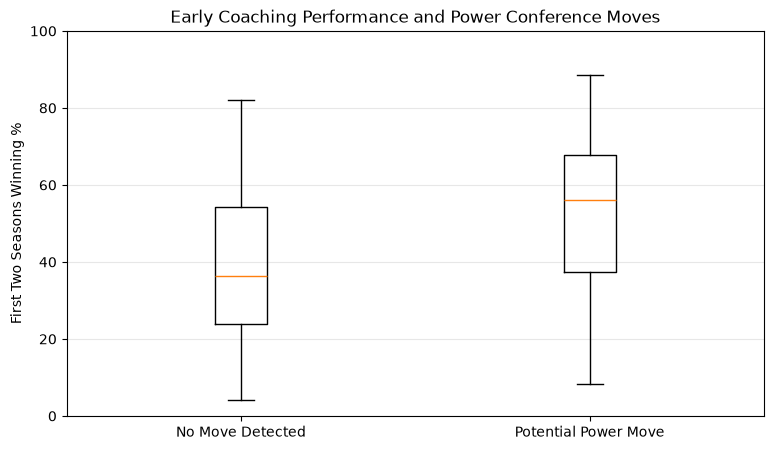

In [61]:

import matplotlib.pyplot as plt

# Separate the two groups
no_move = model_df[
    model_df["potential_power_move"] == 0
]["first_two_win_pct"]

power_move = model_df[
    model_df["potential_power_move"] == 1
]["first_two_win_pct"]

# Create a boxplot
plt.figure(figsize=(9, 5))

plt.boxplot(
    [no_move, power_move],
    tick_labels=["No Move Detected", "Potential Power Move"]
)

plt.ylabel("First Two Seasons Winning %")
plt.title("Early Coaching Performance and Power Conference Moves")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [62]:

# Create winning percentage groups
model_df["win_group"] = pd.cut(
    model_df["first_two_win_pct"],
    bins=[0, 20, 40, 60, 80, 101],
    labels=["0-20%", "20-40%", "40-60%",
            "60-80%", "80-100%"],
    include_lowest=True,
    right=False
)

# Calculate potential Power move rates
win_group_results = model_df.groupby(
    "win_group", observed=True
).agg(
    total_coaches=("coach_id", "count"),
    potential_moves=("potential_power_move", "sum")
)

win_group_results["move_rate"] = (
    win_group_results["potential_moves"] /
    win_group_results["total_coaches"] * 100
).round(2)

display(win_group_results)


,total_coaches,potential_moves,move_rate
win_group,,,
0-20%,32,2,6.25
20-40%,78,14,17.95
40-60%,61,15,24.59
60-80%,53,19,35.85
80-100%,8,7,87.50


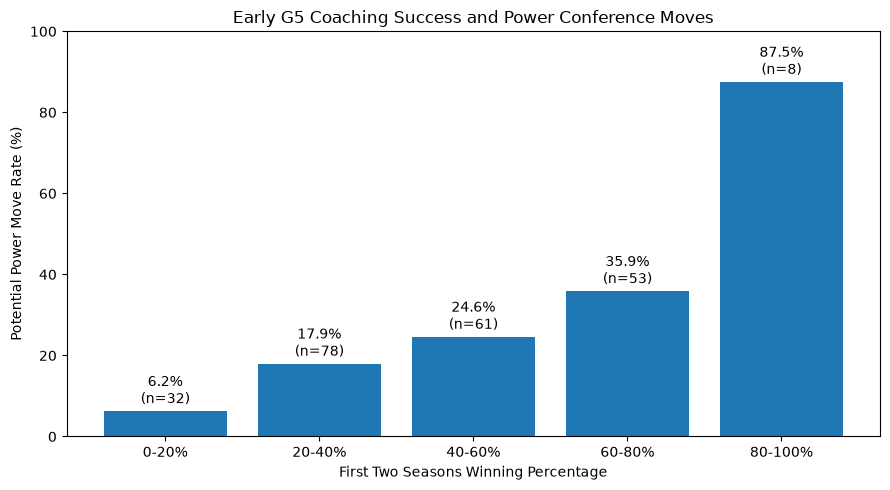

In [63]:

import matplotlib.pyplot as plt

groups = win_group_results.index.astype(str)
rates = win_group_results["move_rate"]
counts = win_group_results["total_coaches"]

plt.figure(figsize=(9, 5))

bars = plt.bar(groups, rates)

plt.xlabel("First Two Seasons Winning Percentage")
plt.ylabel("Potential Power Move Rate (%)")
plt.title("Early G5 Coaching Success and Power Conference Moves")

plt.ylim(0, 100)

for bar, rate, count in zip(bars, rates, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{rate:.1f}%\n(n={count})",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [64]:

# Get the first recorded G5 year for each coach
start_years = first_g5[
    ["coach_id", "year"]
].copy()

start_years = start_years.rename(
    columns={"year": "first_recorded_g5_year"}
)

# Add starting years to our modeling data
cohort_review = model_df.merge(
    start_years,
    on="coach_id",
    how="left"
)

# Find coaches first appearing in 2000
cohort_2000 = cohort_review[
    cohort_review["first_recorded_g5_year"] == 2000
]

print("Total coaches:", len(cohort_review))
print("Coaches first recorded in 2000:", len(cohort_2000))

display(cohort_2000[[
    "coach_name",
    "first_recorded_g5_year",
    "school",
    "first_two_win_pct",
    "career_path"
]].sort_values("coach_name"))


Total coaches: 232
Coaches first recorded in 2000: 43


,coach_name,first_recorded_g5_year,school,first_two_win_pct,career_path
173,Andy McCollum,2000,Middle Tennessee,63.64,No move detected
73,Bill Lynch,2000,Ball State,45.45,Potential First Promotion
98,Bob Pruett,2000,Marshall,73.08,No move detected
176,Bobby Keasler,2000,UL Monroe,13.64,No move detected
180,Chris Scelfo,2000,Tulane,39.13,No move detected
181,Chris Tormey,2000,Nevada,21.74,No move detected
130,Dana Dimel,2000,Houston,13.64,No move detected
184,Darrell Dickey,2000,North Texas,34.78,No move detected
187,Dean Pees,2000,Kent State,31.82,No move detected
32,Fisher DeBerry,2000,Air Force,62.50,No move detected


In [65]:

# Flag coaches first recorded in 2000
cohort_review["needs_history_check"] = (
    cohort_review["first_recorded_g5_year"] == 2000
)

# Temporarily use coaches first recorded after 2000
later_coaches = cohort_review[
    cohort_review["needs_history_check"] == False
].copy()

print("Original coaches:", len(cohort_review))
print("Need history check:",
      cohort_review["needs_history_check"].sum())
print("Later coaches:", len(later_coaches))

# Compare early performance and potential moves
later_comparison = later_coaches.groupby(
    "potential_power_move"
).agg(
    coaches=("coach_id", "count"),
    avg_win_pct=("first_two_win_pct", "mean"),
    avg_improvement=("improvement", "mean")
).round(2)

display(later_comparison)


Original coaches: 232
Need history check: 43
Later coaches: 189


,coaches,avg_win_pct,avg_improvement
potential_power_move,,,
0,136,37.86,1.88
1,53,53.38,11.22


In [66]:

# Make a review table for the 43 coaches
history_review = cohort_2000[[
    "coach_id",
    "coach_name",
    "school",
    "first_recorded_g5_year",
    "first_two_win_pct",
    "career_path"
]].copy()

# Add columns for historical verification
history_review["actual_start_year"] = pd.NA
history_review["started_before_2000"] = pd.NA
history_review["source"] = ""

# Sort by coach name
history_review = history_review.sort_values(
    "coach_name"
)

# Save the review table
history_review.to_csv(
    "g5_coaches_history_review.csv",
    index=False
)

print("Coaches to verify:", len(history_review))
print("Review file saved!")

display(history_review.head(15))


Coaches to verify: 43
Review file saved!


,coach_id,coach_name,school,first_recorded_g5_year,first_two_win_pct,career_path,actual_start_year,started_before_2000,source
173,681,Andy McCollum,Middle Tennessee,2000,63.64,No move detected,<NA>,<NA>,
73,279,Bill Lynch,Ball State,2000,45.45,Potential First Promotion,<NA>,<NA>,
98,387,Bob Pruett,Marshall,2000,73.08,No move detected,<NA>,<NA>,
176,770,Bobby Keasler,UL Monroe,2000,13.64,No move detected,<NA>,<NA>,
180,836,Chris Scelfo,Tulane,2000,39.13,No move detected,<NA>,<NA>,
181,839,Chris Tormey,Nevada,2000,21.74,No move detected,<NA>,<NA>,
130,525,Dana Dimel,Houston,2000,13.64,No move detected,<NA>,<NA>,
184,882,Darrell Dickey,North Texas,2000,34.78,No move detected,<NA>,<NA>,
187,900,Dean Pees,Kent State,2000,31.82,No move detected,<NA>,<NA>,
32,117,Fisher DeBerry,Air Force,2000,62.50,No move detected,<NA>,<NA>,


In [67]:

# Verified coaching start years
verified = {
    "Andy McCollum": (1999, "https://ramblinwreck.com/staff/andy-mccollum"),
    "Bill Lynch": (1995, "https://honorsandawards.iu.edu/awards/honoree/10609.html"),
    "Fisher DeBerry": (1984, "https://footballfoundation.org/honors/college-football-hall-of-fame/fisher-deberry/2309"),
    "Gary Patterson": (2000, "https://gofrogs.com/news/2000/12/8/TCU_Promotes_Patterson_to_Head_Football_Coach"),
    "Joe Novak": (1996, "https://niuhuskies.com/honors/hall-of-fame/joe-novak/135")
}

# Update the review table
for name, (year, source) in verified.items():
    mask = history_review["coach_name"] == name

    history_review.loc[mask, "actual_start_year"] = year
    history_review.loc[mask, "started_before_2000"] = year < 2000
    history_review.loc[mask, "source"] = source

# Save our updated verification file
history_review.to_csv(
    "g5_coaches_history_review.csv",
    index=False
)

# Show our progress
print("Coaches verified:",
      history_review["actual_start_year"].notna().sum())

print("Still need verification:",
      history_review["actual_start_year"].isna().sum())

display(history_review[
    history_review["actual_start_year"].notna()
][[
    "coach_name",
    "actual_start_year",
    "started_before_2000"
]])


Coaches verified: 5
Still need verification: 38


,coach_name,actual_start_year,started_before_2000
173,Andy McCollum,1999,True
73,Bill Lynch,1995,True
32,Fisher DeBerry,1984,True
93,Gary Patterson,2000,False
91,Joe Novak,1996,True


In [68]:

# Next 5 verified coaches
verified_2 = {
    "Bob Pruett": (1997, "https://herdzone.com/news/2006/10/6/The_Robert_L_Bobby_Pruett_Training_Complex_and_the_Jonathan_Edward_Dunfee_Weight_Room_Dedicated"),
    "Chris Scelfo": (1998, "https://tulanegreenwave.com/sports/football/roster/coaches/chris-scelfo/400"),
    "Dana Dimel": (1997, "https://utepminers.com/sports/football/roster/coaches/dana-dimel/2718"),
    "Darrell Dickey": (1998, "https://12thman.com/staff/darrell-dickey"),
    "Jeff Bower": (1990, "https://msfame.com/inductees/jeffrey-bower/")
}

# Update our review table
for name, (year, source) in verified_2.items():
    mask = history_review["coach_name"] == name

    history_review.loc[mask, "actual_start_year"] = year
    history_review.loc[mask, "started_before_2000"] = year < 2000
    history_review.loc[mask, "source"] = source

# Save our progress
history_review.to_csv(
    "g5_coaches_history_review.csv",
    index=False
)

print("Coaches verified:",
      history_review["actual_start_year"].notna().sum())

print("Still need verification:",
      history_review["actual_start_year"].isna().sum())

display(history_review[
    history_review["coach_name"].isin(verified_2.keys())
][[
    "coach_name",
    "actual_start_year",
    "started_before_2000"
]])


Coaches verified: 10
Still need verification: 33


,coach_name,actual_start_year,started_before_2000
98,Bob Pruett,1997,True
180,Chris Scelfo,1998,True
130,Dana Dimel,1997,True
184,Darrell Dickey,1998,True
13,Jeff Bower,1990,True
